DWBI Week 1 Assignment  Tasks 1

Name:shoukat hussain 
Roll No: Bsdsm 039
Section :7A



## Setup

The first cell imports the libraries and locates both data files. If a file is not found, update the path in this cell to match your computer.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def find_file(candidates):
    for name in candidates:
        path = Path(name)
        if path.exists():
            return path
    raise FileNotFoundError(
        "Could not find any of these files: " + ", ".join(candidates) +
        ". Put the dataset beside this notebook or update the path."
    )

messy_path = find_file([
    "DWBI_W1_Messy_Sales_Log.csv",
    "DWBI_W1_Messy_Sales_Log(2).csv"
])
regional_path = find_file([
    "DWBI_W1_Regional_Sales.xlsx",
    "DWBI_W1_Regional_Sales(2).xlsx"
])

messy = pd.read_csv(messy_path)
sales = pd.read_excel(regional_path, sheet_name="Sales")
products = pd.read_excel(regional_path, sheet_name="Products")
regions = pd.read_excel(regional_path, sheet_name="Regions")

print("Messy log:", messy.shape)
print("Sales:", sales.shape, "| Products:", products.shape, "| Regions:", regions.shape)

Messy log: (38, 7)
Sales: (480, 7) | Products: (15, 4) | Regions: (4, 4)


The files load into pandas so the checks are repeatable. The expected Task 5 row counts are 480 sales, 15 products, and 4 regions.

# Task 1 — The messy sales log

## 1.1 Inspect the raw data

The log has mixed date formats, inconsistent labels, text-formatted amounts, and a repeated order. First, the raw values are shown without silently changing them.

In [2]:
display(messy.head(10))
print("\nData types:")
print(messy.dtypes)
print("\nBlank values by column:")
display(messy.isna().sum().rename("Blank count").to_frame())

,OrderID,Branch,Date,Product,Category,Qty,Amount
0,1001,LHR-Gulberg,12/09/2026,Cola 1.5L,Beverages,2,360
1,1002,Lahore Gulberg,2026-09-12,CL-150,Bev.,1,Rs 180
2,1003,KHI-Clifton,09-12-2026,Cola 1.5 Ltr,Beverages,3,540
3,1004,ISB-F7,12 Sep 26,Masala Chips 50g,Snacks,4,200
4,1004,ISB-F7,12 Sep 26,Masala Chips 50g,Snacks,4,200
5,1005,khi clifton,12/09/2026,Fresh Milk 1L,NaN,2,440
6,1006,LHR-Gulberg,2026-09-12,Basmati Rice 5kg,Grocery,1,"2,450"
7,1007,ISB-F7,12/09/2026,LED Bulb 12W,Electrical,-1,-350
8,1008,Lahore Gulberg,12/09/2026,Cola 1.5L,Beverages,2,3600
9,1009,ISB F-7,2026/09/12,Yogurt 500g,Dairy,3,510



Data types:
OrderID      int64
Branch      object
Date        object
Product     object
Category    object
Qty          int64
Amount      object
dtype: object

Blank values by column:


,Blank count
OrderID,0
Branch,0
Date,0
Product,0
Category,2
Qty,0
Amount,0


## 1.2 Data quality issues, evidence, and ownership

The table below lists more than six distinct issues. Ownership means the team that should prevent or resolve the issue; the exact fix depends on whether the correction is mechanical or needs a business decision.

In [3]:
issues = pd.DataFrame([
    {
        "Problem": "Duplicate order row",
        "Example OrderID": "1004",
        "Why it breaks a report": "The same snack sale can be counted twice, inflating quantity and revenue.",
        "Owner": "ETL / Staging",
        "Why this owner": "A repeatable duplicate check can flag identical rows before they enter reporting."
    },
    {
        "Problem": "Inconsistent branch names",
        "Example OrderID": "1001, 1002, 1008, 1011",
        "Why it breaks a report": "One Lahore branch can split into several groups instead of one branch total.",
        "Owner": "ETL / Staging",
        "Why this owner": "A mapping table can standardise known aliases to one branch key."
    },
    {
        "Problem": "Mixed date formats",
        "Example OrderID": "1001, 1002, 1004",
        "Why it breaks a report": "Dates may sort as text or fail date filtering and grouping.",
        "Owner": "Source System",
        "Why this owner": "The branch app should export dates in one consistent, machine-readable format."
    },
    {
        "Problem": "Amount is text / contains currency and separators",
        "Example OrderID": "1002, 1006, 1017",
        "Why it breaks a report": "A numeric sum can fail or skip values such as 'Rs 180' and '2,450'.",
        "Owner": "ETL / Staging",
        "Why this owner": "Currency symbols and separators can be parsed consistently during ingestion."
    },
    {
        "Problem": "Amount inconsistent with quantity and known unit price",
        "Example OrderID": "1008",
        "Why it breaks a report": "Two Cola 1.5L units at Rs 180 each should be Rs 360, not Rs 3,600.",
        "Owner": "Source System",
        "Why this owner": "The checkout system should calculate line amount from quantity and the applied unit price."
    },
    {
        "Problem": "Category is missing",
        "Example OrderID": "1005, 1033",
        "Why it breaks a report": "Milk revenue disappears from category totals or is grouped as blank.",
        "Owner": "Business",
        "Why this owner": "The business must confirm the official category for each milk product before assigning it."
    },
    {
        "Problem": "Product names and product codes are inconsistent",
        "Example OrderID": "1002, 1018, 1021",
        "Why it breaks a report": "CL-150, Cola 1.5L, and similar labels can appear as separate products.",
        "Owner": "ETL / Staging",
        "Why this owner": "A product master mapping can convert known codes and aliases to one product."
    },
    {
        "Problem": "Category labels and capitalization vary",
        "Example OrderID": "1002, 1014, 1013",
        "Why it breaks a report": "Bev., Beverages, snacks, and grocery can become separate category groups.",
        "Owner": "ETL / Staging",
        "Why this owner": "A controlled mapping can standardise category labels once the business definitions are known."
    },
    {
        "Problem": "Negative quantity and amount may represent a return",
        "Example OrderID": "1007",
        "Why it breaks a report": "If returns are not consistently represented, sales can be overstated or net sales misread.",
        "Owner": "Business",
        "Why this owner": "The business must define whether and how returns are included in the sales metric."
    },
    {
        "Problem": "Branch labels include punctuation and spacing variants",
        "Example OrderID": "1009, 1019, 1025",
        "Why it breaks a report": "ISB-F7 and ISB F-7 can be treated as different branches.",
        "Owner": "ETL / Staging",
        "Why this owner": "A branch reference table can standardise formatting and aliases."
    }
])
display(issues)

,Problem,Example OrderID,Why it breaks a report,Owner,Why this owner
0,Duplicate order row,1004,"The same snack sale can be counted twice, infl...",ETL / Staging,A repeatable duplicate check can flag identica...
1,Inconsistent branch names,"1001, 1002, 1008, 1011",One Lahore branch can split into several group...,ETL / Staging,A mapping table can standardise known aliases ...
2,Mixed date formats,"1001, 1002, 1004",Dates may sort as text or fail date filtering ...,Source System,The branch app should export dates in one cons...
3,Amount is text / contains currency and separators,"1002, 1006, 1017",A numeric sum can fail or skip values such as ...,ETL / Staging,Currency symbols and separators can be parsed ...
4,Amount inconsistent with quantity and known un...,1008,Two Cola 1.5L units at Rs 180 each should be R...,Source System,The checkout system should calculate line amou...
5,Category is missing,"1005, 1033",Milk revenue disappears from category totals o...,Business,The business must confirm the official categor...
6,Product names and product codes are inconsistent,"1002, 1018, 1021","CL-150, Cola 1.5L, and similar labels can appe...",ETL / Staging,A product master mapping can convert known cod...
7,Category labels and capitalization vary,"1002, 1014, 1013","Bev., Beverages, snacks, and grocery can becom...",ETL / Staging,A controlled mapping can standardise category ...
8,Negative quantity and amount may represent a r...,1007,"If returns are not consistently represented, s...",Business,The business must define whether and how retur...
9,Branch labels include punctuation and spacing ...,"1009, 1019, 1025",ISB-F7 and ISB F-7 can be treated as different...,ETL / Staging,A branch reference table can standardise forma...


Two issues that could have been prevented at entry are the inconsistent date format and the incorrect line amount. The branch system should enforce a date field with one export format, and calculate Amount automatically as Quantity × the actual unit price rather than allowing staff to type it.

## 1.3 Calculate Beverages revenue

**Assumptions used:** order 1004 is a duplicate but it is not a beverage sale; 1008 is corrected from Rs 3,600 to Rs 360 because 2 × Rs 180 = Rs 360; negative quantities are treated as returns and included as negative revenue only if they belong to Beverages; missing categories are not silently guessed. Orders 1005 and 1033 are milk items with blank categories, so I leave them out of Beverages until the business confirms their category. The amount field is parsed into numbers before calculating.

In [4]:
# Keep the raw data unchanged and create cleaned working columns.
work = messy.copy()
work["Amount_raw"] = work["Amount"].astype(str)
work["Amount_num"] = (
    work["Amount_raw"]
    .str.replace(",", "", regex=False)
    .str.replace("Rs", "", regex=False)
    .str.strip()
)
work["Amount_num"] = pd.to_numeric(work["Amount_num"], errors="coerce")

# Normalise category labels only where the label is already clear.
category_map = {
    "bev.": "Beverages", "beverages": "Beverages",
    "snacks": "Snacks", "grocery": "Grocery", "dairy": "Dairy",
    "electrical": "Electrical", "electronics": "Electrical"
}
work["Category_norm"] = work["Category"].astype("string").str.strip().str.lower().map(category_map)

# Remove exact duplicate records for analysis.
work = work.drop_duplicates()

# The brief points out that order 1008 is a ten-times amount error.
work.loc[work["OrderID"].astype(str).eq("1008"), "Amount_num"] = 360

beverage_rows = work[work["Category_norm"].eq("Beverages")].copy()
display(beverage_rows[["OrderID", "Product", "Qty", "Amount_raw", "Amount_num"]])

beverage_total = beverage_rows["Amount_num"].sum()
print(f"Corrected Beverages revenue: Rs {beverage_total:,.0f}")

,OrderID,Product,Qty,Amount_raw,Amount_num
0,1001,Cola 1.5L,2,360,360
1,1002,CL-150,1,Rs 180,180
2,1003,Cola 1.5 Ltr,3,540,540
8,1008,Cola 1.5L,2,3600,360
10,1010,Orange Juice 1L,1,320,320
15,1015,Orange Juice 1L,3,960,960
18,1018,OJ-1L,4,"1,280",1280
21,1021,CL-150,2,360,360
25,1025,Orange Juice 1L,2,640,640
30,1030,Cola 1.5L,1,180,180


Corrected Beverages revenue: Rs 6,320


The corrected total is calculated from rows whose category can be identified as Beverages, after removing exact duplicate rows and fixing the clearly incorrect amount on order 1008. Based on the supplied rows and these assumptions, the total should be **Rs 6,320**.

## 1.4 Confidence and dashboard decision

**Confidence: Medium.** The arithmetic is reproducible, but the missing categories on orders 1005 and 1033 need a business decision, and the return policy should be confirmed. Confidence would improve with a product master, branch master, return rules, and the original checkout transaction or price record.

This file should not be loaded directly into a dashboard because duplicate rows, inconsistent labels, missing categories, mixed data types, and a wrong amount can produce misleading totals.

# Task 2 — OLTP or OLAP?

OLTP handles current transactions with quick, small writes. OLAP is used to compare and summarise many records over time.

In [5]:
oltp_olap = pd.DataFrame([
    (1, "A cashier scans a packet of chips and prints the bill", "OLTP", "It records one current sale and must respond quickly at checkout."),
    (2, "The CEO compares sales by category over the last 12 months", "OLAP", "It aggregates many transactions across a long period."),
    (3, "A customer updates her phone number in the store app", "OLTP", "It updates one customer's current record."),
    (4, "Marketing compares Eid week with a normal week, across all branches", "OLAP", "It compares grouped sales across branches and time periods."),
    (5, "You withdraw Rs 5,000 from an ATM", "OLTP", "It must safely record a current account transaction immediately."),
    (6, "A bank finds customers whose balance fell three months in a row", "OLAP", "It looks for a pattern across customer balances over multiple months."),
    (7, "A rider marks a food order as delivered", "OLTP", "It changes the current status of one operational order."),
    (8, "Head office ranks all branches by returns this quarter", "OLAP", "It summarises and ranks branch performance over a quarter.")
], columns=["#", "Scenario", "Class", "Reason"])
display(oltp_olap)

,#,Scenario,Class,Reason
0,1,A cashier scans a packet of chips and prints t...,OLTP,It records one current sale and must respond q...
1,2,The CEO compares sales by category over the la...,OLAP,It aggregates many transactions across a long ...
2,3,A customer updates her phone number in the sto...,OLTP,It updates one customer's current record.
3,4,Marketing compares Eid week with a normal week...,OLAP,It compares grouped sales across branches and ...
4,5,"You withdraw Rs 5,000 from an ATM",OLTP,It must safely record a current account transa...
5,6,A bank finds customers whose balance fell thre...,OLAP,It looks for a pattern across customer balance...
6,7,A rider marks a food order as delivered,OLTP,It changes the current status of one operation...
7,8,Head office ranks all branches by returns this...,OLAP,It summarises and ranks branch performance ove...


## Two examples from Pakistani businesses

- **OLTP:** A cashier at a Lahore grocery store scans items and records payment. It updates a current transaction and needs a quick response.
- **OLAP:** A telecom company compares monthly recharge revenue by city and package. It aggregates large volumes of history to support planning.

## Borderline case

A store supervisor checks today's sales every hour. This looks operational because it is about today, but the report reads and aggregates many checkout transactions. I would run it from a reporting copy or warehouse (OLAP), so repeated reads do not slow down checkout writes. The source transactions still remain in OLTP.

## Why the live checkout database slowed down

The CEO's report likely read and grouped many rows, using database resources for scans, joins, sorting, and aggregation. OLTP systems are tuned for fast, small transactions and many concurrent writes, not large historical queries. At 6 pm on Friday, that report could compete with checkout inserts and updates for CPU, memory, disk I/O, and locks, making bills slower.

# Task 3 — No history, no single truth

## 3.1 No history: Ali moved branches

This breaks **time-variance** because the live Employee row only stores Ali's current branch, not the branch that applied at the time of each sale. It can also expose a weakness in integration if branch assignments are not consistently linked to sales.

A warehouse can keep dated versions of employee assignments. For example, Ali's Lahore assignment can have an end date in March and his Karachi assignment can start then. Reports for earlier sales use the assignment valid on the sale date, so Lahore keeps credit for the earlier period.

Another example is a product price: overwriting last month's price with today's price can make old margin reports appear to use the new price.

## 3.2 No single truth: different sales totals

- **Operations — Rs 661.65 m:** might count orders when placed, including orders later cancelled or returned.
- **Finance — Rs 283.70 m:** might report invoiced net sales after returns, discounts, and accounting adjustments.
- **Sales — Rs 584.75 m:** might count fulfilled orders or use a different cut-off date.

These can differ without arithmetic mistakes because the departments are using different definitions, filters, and time cut-offs.

A shared staging process applies consistent cleaning, mappings, and validation before the data reaches reporting. The business owners should agree on the definition of “sales last month,” with Finance and Sales stakeholders involved, then document the rule and use it consistently. Each department can still have different views, but they should not quietly redefine the shared metric.

## 3.3 Why build a warehouse?

The live systems are built to run transactions, not to preserve every historical version or provide one agreed definition for every report. A warehouse keeps time-aware history and brings data from different systems through common cleaning and definitions. That helps explain what happened in the past and reduces arguments over which department's number is correct.

**Non-volatile** means warehouse records are generally loaded and queried rather than changed by everyday operational transactions; controlled corrections and maintenance can still happen. For example, a documented ETL correction can fix a wrongly mapped product key in the warehouse.

# Task 4 — DW/BI architecture

The flow is Source Systems → ETL / Staging → Presentation Area → BI Applications. Each item below is assigned to one stage.

In [6]:
architecture_items = pd.DataFrame([
    ("A", "Removing duplicate orders", "ETL / Staging", "Duplicates are detected and removed during data preparation."),
    ("B", "CEO dashboard on a phone", "BI Applications", "It is a report interface used by decision-makers."),
    ("C", "Branch POS billing system", "Source Systems", "It records the original checkout transactions."),
    ("D", "Sales star schema by date, branch, product", "Presentation Area", "It is a curated model designed for consistent analysis."),
    ("E", "HR team's staff Excel sheet", "Source Systems", "It is an upstream file containing business data."),
    ("F", "Converting CL-150 to Cola 1.5L", "ETL / Staging", "It standardises a source product code during ingestion."),
    ("G", "Weekly PDF report emailed to managers", "BI Applications", "It presents results to report consumers."),
    ("H", "Finance data mart", "Presentation Area", "It is a prepared subject-area dataset for reporting.")
], columns=["Item", "Description", "Stage", "Reason"])
display(architecture_items)

,Item,Description,Stage,Reason
0,A,Removing duplicate orders,ETL / Staging,Duplicates are detected and removed during dat...
1,B,CEO dashboard on a phone,BI Applications,It is a report interface used by decision-makers.
2,C,Branch POS billing system,Source Systems,It records the original checkout transactions.
3,D,"Sales star schema by date, branch, product",Presentation Area,It is a curated model designed for consistent ...
4,E,HR team's staff Excel sheet,Source Systems,It is an upstream file containing business data.
5,F,Converting CL-150 to Cola 1.5L,ETL / Staging,It standardises a source product code during i...
6,G,Weekly PDF report emailed to managers,BI Applications,It presents results to report consumers.
7,H,Finance data mart,Presentation Area,It is a prepared subject-area dataset for repo...


## Architecture diagram

This diagram is drawn in the notebook rather than copied from a slide. The item letters correspond to the table above.

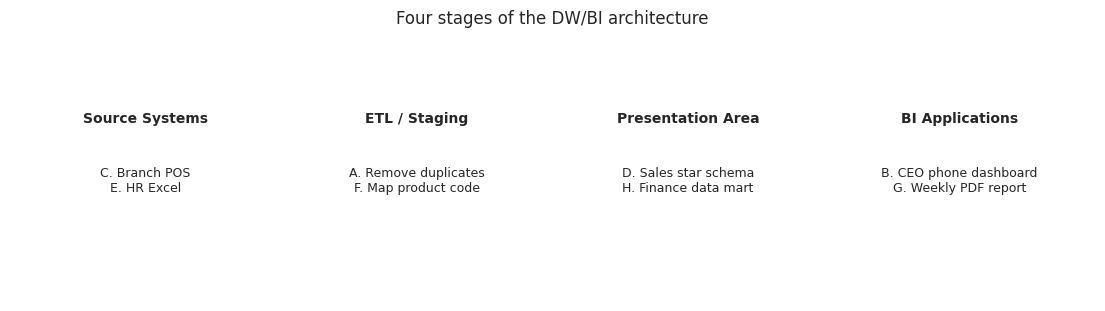

In [7]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.axis("off")
stages = [
    ("Source Systems", "C. Branch POS\nE. HR Excel"),
    ("ETL / Staging", "A. Remove duplicates\nF. Map product code"),
    ("Presentation Area", "D. Sales star schema\nH. Finance data mart"),
    ("BI Applications", "B. CEO phone dashboard\nG. Weekly PDF report")
]
xs = [0.02, 0.27, 0.52, 0.77]
for x, (title, body) in zip(xs, stages):
    ax.add_patch(plt.Rectangle((x, 0.25), 0.21, 0.55, fill=False, linewidth=1.8, transform=ax.transAxes))
    ax.text(x + 0.105, 0.68, title, ha="center", va="center", weight="bold", transform=ax.transAxes, fontsize=10)
    ax.text(x + 0.105, 0.45, body, ha="center", va="center", transform=ax.transAxes, fontsize=9)
for x in [0.235, 0.485, 0.735]:
    ax.annotate("", xy=(x + 0.03, 0.52), xytext=(x - 0.005, 0.52),
                xycoords=ax.transAxes, textcoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->", linewidth=1.8))
plt.title("Four stages of the DW/BI architecture")
plt.show()

## Restaurant metaphor

- **A diner grabs food from the stove:** a report queries operational source tables directly. This can bypass the prepared model and compete with live transactions.
- **The kitchen serves without tasting:** unvalidated data reaches reports. Wrong totals and missing values can reach managers.
- **Two kitchens use different recipes:** teams clean or define the same metric differently. They produce different totals for what should be the same question.

## Three goals and what would violate them

1. **Consistent information:** if Lahore is written as `LHR-Gulberg` in one file and `Lahore Gulberg` in another, branch totals split.
2. **Accessible information:** if a manager can only get a report by asking an analyst to query the live checkout system, access is slow and risky.
3. **Adaptable reporting:** if every new category question requires rewriting the POS application, the design is not flexible enough for analysis.

## Is the HR Excel sheet a source system?

**For:** it may be the only place where HR maintains staff details, so it is a real upstream source.  
**Against:** it may have inconsistent formats, manual edits, duplicates, and no reliable change history.  
**Choice:** treat it as a source, but do not trust it automatically. Require a named owner, documented columns, controlled access, validation rules, a refresh schedule, and checks for duplicates and missing staff IDs before loading it.

# Task 5 — Regional sales analysis

## Before connecting to Power BI

1. **What product was sold?** `Sales[ProductID]` identifies the product; join it to `Products[ProductID]` to show the product name.
2. **Where does region name live?** In `Regions[RegionName]`, linked through `RegionID`.
3. **Where should Product Category come from?** Use `Products[Category]`, because category describes a product and the Products table provides one consistent category per ProductID. Sales contains transaction keys and amounts, not the product attributes.

## 5.1 Load and check the tables

In [8]:
print("Sales rows/columns:", sales.shape)
print("Products rows/columns:", products.shape)
print("Regions rows/columns:", regions.shape)

assert sales.shape == (480, 7), "Sales shape differs from the assignment brief."
assert products.shape == (15, 4), "Products shape differs from the assignment brief."
assert regions.shape == (4, 4), "Regions shape differs from the assignment brief."

display(sales.head())
display(products.head())
display(regions)

Sales rows/columns: (480, 7)
Products rows/columns: (15, 4)
Regions rows/columns: (4, 4)


,SaleID,SaleDate,ProductID,RegionID,Quantity,UnitPrice,SalesAmount
0,S1001,2026-01-01,P05,R1,10,120,1200
1,S1002,2026-01-01,P11,R3,1,1890,1890
2,S1003,2026-01-02,P07,R3,10,220,2200
3,S1004,2026-01-03,P02,R3,7,320,2240
4,S1072,2026-01-01,P05,R1,4,120,480


,ProductID,ProductName,Category,UnitPrice
0,P01,Cola 1.5L,Beverages,180
1,P02,Orange Juice 1L,Beverages,320
2,P03,Mineral Water 1.5L,Beverages,60
3,P04,Masala Chips 50g,Snacks,50
4,P05,Salted Biscuits Pack,Snacks,120


,RegionID,RegionName,HeadOffice,RegionalManager
0,R1,Central,Lahore,Ayesha Siddiqui
1,R2,North,Islamabad,Bilal Ahmed
2,R3,South,Karachi,Hina Raza
3,R4,West,Peshawar,Kamran Khan


The table sizes match the assignment brief: 480 sales, 15 products, and 4 regions. In Power BI, use **Get Data → Excel workbook**, select all three sheets, and load them without editing the source workbook.

## 5.2 Check relationships and key quality

`Products[ProductID]` and `Regions[RegionID]` should be the **one** side because each key should appear once in its lookup table. `Sales[ProductID]` and `Sales[RegionID]` are the **many** sides because many transactions can refer to the same product or region.

In [9]:
# Check whether lookup keys are unique and whether sales keys match the lookup tables.
print("Unique ProductID in Products:", products["ProductID"].is_unique)
print("Unique RegionID in Regions:", regions["RegionID"].is_unique)

unknown_products = sorted(set(sales["ProductID"].dropna()) - set(products["ProductID"].dropna()))
unknown_regions = sorted(set(sales["RegionID"].dropna()) - set(regions["RegionID"].dropna()))
print("Sales ProductIDs missing from Products:", unknown_products)
print("Sales RegionIDs missing from Regions:", unknown_regions)

print("\nBlank values:")
display(pd.DataFrame({
    "Sales": sales.isna().sum(),
    "Products": products.isna().sum(),
    "Regions": regions.isna().sum()
}).fillna(0).astype(int))

Unique ProductID in Products: True
Unique RegionID in Regions: True
Sales ProductIDs missing from Products: []
Sales RegionIDs missing from Regions: []

Blank values:


,Sales,Products,Regions
Category,0,0,0
HeadOffice,0,0,0
ProductID,0,0,0
ProductName,0,0,0
Quantity,0,0,0
RegionID,0,0,0
RegionName,0,0,0
RegionalManager,0,0,0
SaleDate,0,0,0
SaleID,0,0,0


The checks show whether the lookup keys are unique and whether every sales key can find a matching lookup row. In Power BI Model view, create one-to-many relationships from Products to Sales on ProductID and Regions to Sales on RegionID, with filtering flowing from lookup tables to Sales.

## 5.3 Total Sales by Region

This uses the region name rather than the ID. The chart title states the result after the calculation, and the printed table gives the exact values behind the visual.

,RegionName,SalesAmount
2,South,1118940
0,Central,943410
1,North,637340
3,West,327300


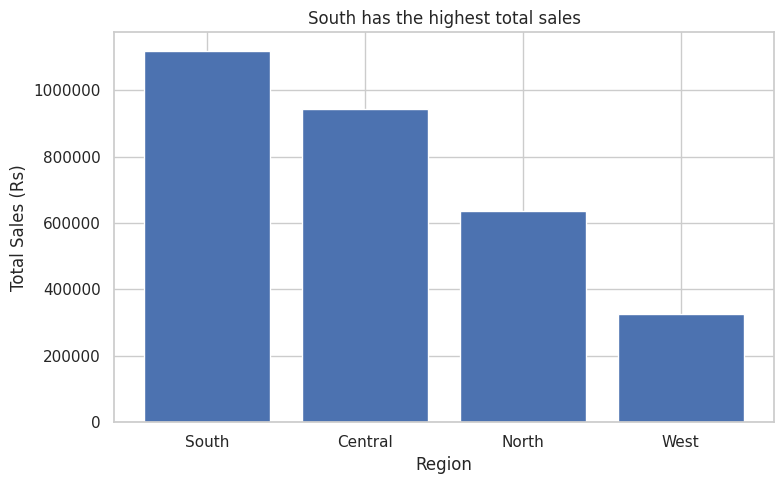

In [10]:
sales_region = (
    sales.merge(regions[["RegionID", "RegionName"]], on="RegionID", how="left", validate="many_to_one")
         .groupby("RegionName", as_index=False)["SalesAmount"].sum()
         .sort_values("SalesAmount", ascending=False)
)
display(sales_region)

top_region = sales_region.iloc[0]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(sales_region["RegionName"], sales_region["SalesAmount"])
ax.set_title(f"{top_region['RegionName']} has the highest total sales")
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales (Rs)")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

The chart groups SalesAmount by RegionName after joining the Regions table. In Power BI, use RegionName for the axis and Sum of SalesAmount for values, then sort descending; without the relationship, each region may incorrectly show the same overall total.

## 5.4 Product Category slicer and Total Sales card

The category filter must come from Products. The table and chart below imitate the Power BI slicer/card interaction by calculating totals for each category, including a check that the category totals add back to the unfiltered total.

,Total Sales by Category
Category,
Electronics,1762350
Grocery,965460
Dairy,157920
Beverages,82340
Snacks,58920


Card total with no category selected: Rs 3,026,990
Sum of category totals: Rs 3,026,990
Category totals reconcile: True


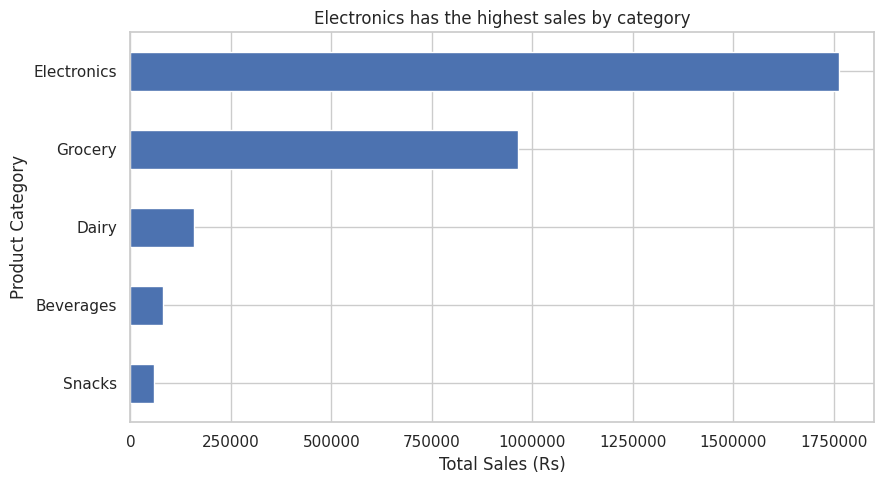

In [11]:
sales_detail = (
    sales.merge(products[["ProductID", "ProductName", "Category", "UnitPrice"]].rename(
        columns={"UnitPrice": "ProductMasterUnitPrice"}
    ), on="ProductID", how="left", validate="many_to_one")
)

total_sales = sales["SalesAmount"].sum()
category_sales = sales_detail.groupby("Category", dropna=False)["SalesAmount"].sum().sort_values(ascending=False)
display(category_sales.rename("Total Sales by Category").to_frame())

print(f"Card total with no category selected: Rs {total_sales:,.0f}")
print(f"Sum of category totals: Rs {category_sales.sum():,.0f}")
print("Category totals reconcile:", np.isclose(category_sales.sum(), total_sales))

fig, ax = plt.subplots(figsize=(9, 5))
category_sales.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Beverages contribute the most sales by product category" if category_sales.index[0] == "Beverages"
             else f"{category_sales.index[0]} has the highest sales by category")
ax.set_xlabel("Total Sales (Rs)")
ax.set_ylabel("Product Category")
ax.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In Power BI, add a slicer using `Products[Category]` and a card using `SUM(Sales[SalesAmount])`. Click each category and check that both the regional chart and the card change; selecting categories one by one should reconcile to the same overall total when the categories are mutually exclusive and all rows have a category.

## 5.5 Validate the SalesAmount total and category split

This section checks the source total, category reconciliation, and whether `SalesAmount` matches `Quantity × Sales[UnitPrice]`. The transaction-level UnitPrice is used for revenue validation because it is the price recorded on that sale; `Products[UnitPrice]` is a product master/list price and may change independently.

In [12]:
source_total = sales["SalesAmount"].sum()
calculated_total = (sales["Quantity"] * sales["UnitPrice"]).sum()
line_amount_mismatches = sales.loc[
    ~np.isclose(sales["SalesAmount"], sales["Quantity"] * sales["UnitPrice"]),
    ["SaleID", "Quantity", "UnitPrice", "SalesAmount"]
]

print(f"Sum of SalesAmount across 480 rows: Rs {source_total:,.0f}")
print(f"Sum of Quantity × Sales[UnitPrice]: Rs {calculated_total:,.0f}")
print("SalesAmount equals Quantity × transaction UnitPrice on every row:",
      line_amount_mismatches.empty)
display(line_amount_mismatches.head(20))

category_totals = sales_detail.groupby("Category")["SalesAmount"].sum()
print("Category sum equals overall total:", np.isclose(category_totals.sum(), source_total))
print("Source workbook was read only; this notebook does not write to or modify it.")

Sum of SalesAmount across 480 rows: Rs 3,026,990
Sum of Quantity × Sales[UnitPrice]: Rs 3,026,990
SalesAmount equals Quantity × transaction UnitPrice on every row: True


,SaleID,Quantity,UnitPrice,SalesAmount


Category sum equals overall total: True
Source workbook was read only; this notebook does not write to or modify it.
